# **MEJOR MODELO PUMP IT UP - JAIME DE VERA MARTÍN**

---

---



Tanzania se enfrenta a una crisis de infraestructura en donde muchos pozos de agua y bombas están instalados por todo el país, pero muchos están rotos o a punto de romperse.
Este concurso de https://www.drivendata.org/ propone construir un modelo de Machine Learning capaz de predecir el estado operativo de cada bomba para salvar recursos y garantizar el acceso al agua potable a miles de personas.

-----------------Metodología---------------------
1. *EDA inicial*
2. *Feature Engineering y limpieza*
3. *EDA post-limpieza*
4. *Preprocesamiento*
5. *Modelado*
6. *Interpretabilidad*
7. *Evaluación y exportación*

---

---



### **CONEXIÓN A GOOGLE DRIVE**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **INSTALACIÓN DE LIBRERÍAS**

In [ ]:
!pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.4/400.4 kB 230.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 204.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 161.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 195.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 132.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 299.8 kB/s eta 0:00:00


### **IMPORTACIÓN DE LIBRERIAS**

In [ ]:
# Análisis y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from ydata_profiling import ProfileReport

# Arquitectura ML
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder

# Modelado y evaluación
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

### **CREACIÓN DE DATAFRAMES**

In [ ]:
# Tras echar un vistazo al Dataset, convertimos las fechas a formato `Datetime` y marcamos el índice

X_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

y_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetLabels.csv',
                          sep=',',
                          index_col='id')

X_test_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TestSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

# Mapeo de la variable objetivo a formato numérico
y = y_train_original['status_group'].map({'non functional': 0, 'functional needs repair': 1, 'functional': 2})

print(f'Dimensiones de X_train_original: {X_train_original.shape}')
print(f'Dimensiones de y_train_original: {y_train_original.shape}')
print(f'Dimensiones de X_test_original: {X_test_original.shape}')

Dimensiones de X_train_original: (59400, 39)
Dimensiones de y_train_original: (59400, 1)
Dimensiones de X_test_original: (14850, 39)


### **EDA INICIAL**

Antes de programar ninguna solución, hay que diagnosticar los datos. En esta fase se busca responder a tres preguntas vitales que marcarán la estrategia:
1. ¿Existe un desbalanceo de clases? Es decir, ¿Hay más pozos sanos que rotos o que necesitan reparación?.
2. ¿Hay errores humanos en el registro?
3. ¿Tienen sentido las variables numéricas para el modelo?

In [ ]:
print('=' * 50)
print('Vistazo a las primeras filas:')
print('=' * 50,'\n')
X_train_original.head(3)

Vistazo a las primeras filas:



,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
id,,,,,,,,,,,,,,,,,,,,,
69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,...,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,...,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,...,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe


In [ ]:
print('=' * 50)
print('Tipos de datos y nulos:')
print('=' * 50,'\n')
X_train_original.info()

Tipos de datos y nulos:

<class 'pandas.core.frame.DataFrame'>
Index: 59400 entries, 69572 to 26348
Data columns (total 39 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   amount_tsh             59400 non-null  float64       
 1   date_recorded          59400 non-null  datetime64[ns]
 2   funder                 55763 non-null  object        
 3   gps_height             59400 non-null  int64         
 4   installer              55745 non-null  object        
 5   longitude              59400 non-null  float64       
 6   latitude               59400 non-null  float64       
 7   wpt_name               59398 non-null  object        
 8   num_private            59400 non-null  int64         
 9   basin                  59400 non-null  object        
 10  subvillage             59029 non-null  object        
 11  region                 59400 non-null  object        
 12  region_code            59400 non-nul

In [ ]:
print('=' * 50)
print('Resumen estadístico:')
print('=' * 50, '\n')
X_train_original.describe()

Resumen estadístico:



,amount_tsh,date_recorded,gps_height,longitude,latitude,num_private,region_code,district_code,population,construction_year
count,59400.000000,59400,59400.000000,59400.000000,5.940000e+04,59400.000000,59400.000000,59400.000000,59400.000000,59400.000000
mean,317.650385,2012-03-29 09:11:33.818181888,668.297239,34.077427,-5.706033e+00,0.474141,15.297003,5.629747,179.909983,1300.652475
min,0.000000,2002-10-14 00:00:00,-90.000000,0.000000,-1.164944e+01,0.000000,1.000000,0.000000,0.000000,0.000000
25%,0.000000,2011-04-01 00:00:00,0.000000,33.090347,-8.540621e+00,0.000000,5.000000,2.000000,0.000000,0.000000
50%,0.000000,2012-10-10 00:00:00,369.000000,34.908743,-5.021597e+00,0.000000,12.000000,3.000000,25.000000,1986.000000
75%,20.000000,2013-02-09 00:00:00,1319.250000,37.178387,-3.326156e+00,0.000000,17.000000,5.000000,215.000000,2004.000000
max,350000.000000,2013-12-03 00:00:00,2770.000000,40.345193,-2.000000e-08,1776.000000,99.000000,80.000000,30500.000000,2013.000000
std,2997.574558,NaN,693.116350,6.567432,2.946019e+00,12.236230,17.587406,9.633649,471.482176,951.620547


In [ ]:
profile = ProfileReport(X_train_original, title='Informe Pump It Up')

profile

# Para guardarlo en un archivo .html y no tener que estar ejecutándolo todo el rato:
#profile.to_file("informe_eda_inicial_profile.html")

Output hidden; open in https://colab.research.google.com to view.

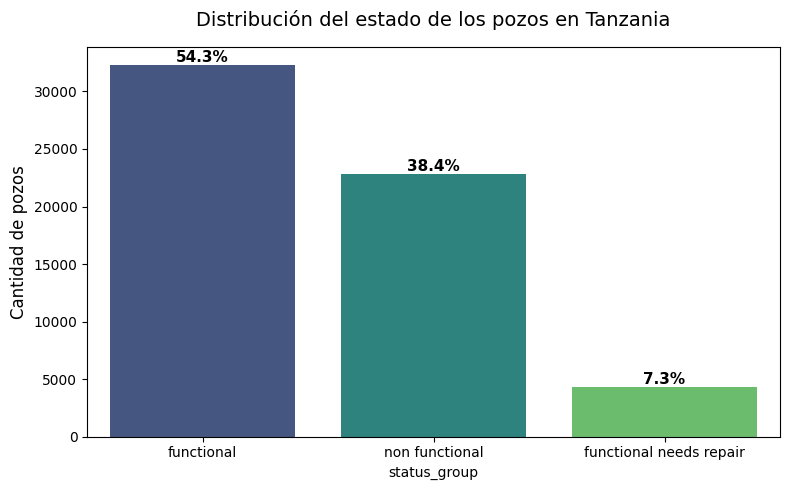

In [ ]:
plt.figure(figsize = (8, 5))
ax = sns.countplot(data=y_train_original, x='status_group', hue='status_group',
                   order=['functional', 'non functional', 'functional needs repair'],
                   palette='viridis', legend=False)

plt.title('Distribución del estado de los pozos en Tanzania', fontsize=14, pad=15)
plt.ylabel('Cantidad de pozos', fontsize=12)

total = len(y_train_original)
for p in ax.patches:
    porcentaje = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y_pos = p.get_height()
    ax.annotate(porcentaje, (x, y_pos), ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

Gracias a toda la exploración anterior (y a los 15 intentos anteriores), hemos diagnosticado los síntomas del dataset, por lo que hay que aplicar la medicina antes de dárselo al modelo. Estas son nuestras 4 decisiones estratégicas:

1. **Ingeniería de variables y transformaciones matemáticas:**
   * El modelo no entiende fechas crudas, así que crearemos la variable `antiguedad`.
   * Extraeremos el mes para crear `temporada_seca`, ya que las sequías en Tanzania (Junio-Octubre) deterioran las bombas de agua. Además, convertiremos el mes a `str` para que el algoritmo lo trate como una categoría y no asuma que diciembre (12) vale más que enero (1).
   * Proyección espacial 3D: los modelos basados en árboles cortan los mapas en cuadrados, pero la Tierra es esférica. Aplicaremos trigonometría a la latitud y longitud para crear coordenadas cartesianas (`geo_x`, `geo_y`, `geo_z`), permitiendo al modelo trazar fronteras diagonales y curvas.

2. **Caza de los ceros falsos:**
   * En el `.describe()` vimos que el valor mínimo de la Longitud, Altitud y Población es 0; y un pozo en Tanzania no puede estar en las coordenadas (0,0), por lo que son nulos camuflados. Los convertiremos a `NaN` para que el algoritmo los procese correctamente.

3. **Anti-Overfitting:**
   * Borraremos columnas redundantes y todo el texto de alta cardinalidad o geografía específica que hace que el modelo memorice y falle.

4. **Tratamiento de booleanos nulos:**
   * Las variables de permisos (`permit`, `public_meeting`) tienen valores faltantes. Los rellenaremos con la etiqueta `Unknown` para que el modelo pueda aprender de la ausencia de información.

### **FEATURE ENGINEERING Y LIMPIEZA**

In [ ]:
def limpieza(df):
    df_clean = df.copy()

    # Feature Engineering: tiempo y clima
    df_clean['antiguedad'] = df_clean['date_recorded'].dt.year - df_clean['construction_year']
    df_clean['mes_registro'] = df_clean['date_recorded'].dt.month.astype(str)
    df_clean['temporada_seca'] = df_clean['date_recorded'].dt.month.apply(lambda x: 1 if x in [6, 7, 8, 9, 10] else 0)

    # Caza de ceros
    for col in ['longitude', 'population', 'gps_height']:
        df_clean[col] = df_clean[col].replace(0, np.nan)

    df_clean['antiguedad'] = df_clean['antiguedad'].apply(lambda x: np.nan if x > 100 or x < 0 else x)
    df_clean['latitude'] = df_clean['latitude'].apply(lambda x: np.nan if x > -1e-6 else x)

    # Proyección espacial 3D
    lat_rad = np.radians(df_clean['latitude'])
    lon_rad = np.radians(df_clean['longitude'])

    df_clean['geo_x'] = np.cos(lat_rad) * np.cos(lon_rad)
    df_clean['geo_y'] = np.cos(lat_rad) * np.sin(lon_rad)
    df_clean['geo_z'] = np.sin(lat_rad)

    # Tratamiento de booleanos
    for col in ['public_meeting', 'permit']:
        df_clean[col] = df_clean[col].fillna('Unknown').astype(str)

    # Anti-Overfitting
    columnas_a_borrar = [
        'date_recorded', 'construction_year', 'recorded_by', 'num_private', 'wpt_name',
        'scheme_name', 'subvillage', 'ward', 'extraction_type_group', 'extraction_type_class',
        'management_group', 'scheme_management', 'payment_type', 'quality_group',
        'quantity_group', 'source_type', 'source_class', 'waterpoint_type_group',
        'funder', 'installer', 'lga', 'basin', 'region', 'region_code']

    df_clean.drop(columns=columnas_a_borrar, inplace=True, errors='ignore')

    return df_clean

# Aplicamos
X_train_limpio = limpieza(X_train_original)

### **EDA POST-LIMPIEZA**

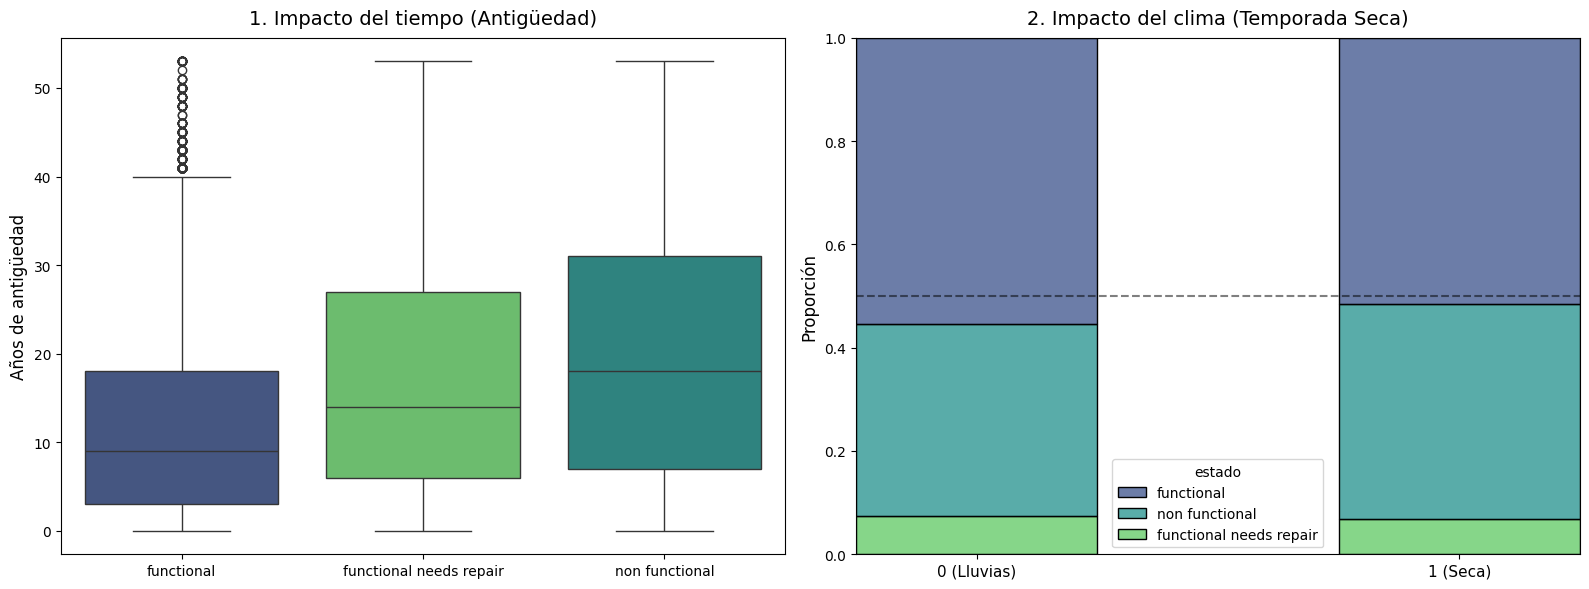

In [ ]:
# Unimos temporalmente X_train_limpio con el estado real del pozo
df_eda = X_train_limpio.copy()
df_eda['estado'] = y_train_original['status_group']

# GRÁFICOS:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

  # Gráfico 1: Antigüedad
sns.boxplot(
    ax=axes[0], data=df_eda, x='estado', y='antiguedad', hue='estado',
    palette='viridis', order=['functional', 'functional needs repair', 'non functional'], legend=False)

axes[0].set_title('1. Impacto del tiempo (Antigüedad)', fontsize=14, pad=10)
axes[0].set_xlabel('', fontsize=12)
axes[0].set_ylabel('Años de antigüedad', fontsize=12)

# Grñafico 2: Temporada Seca
sns.histplot(
    ax=axes[1], data=df_eda, x='temporada_seca', hue='estado',
    multiple='fill', palette='viridis', shrink=0.5, discrete=True)

axes[1].set_title('2. Impacto del clima (Temporada Seca)', fontsize=14, pad=10)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['0 (Lluvias)', '1 (Seca)'], fontsize=11)
axes[1].set_xlabel('', fontsize=12)
axes[1].set_ylabel('Proporción', fontsize=12)
axes[1].axhline(0.5, color='black', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Gráfico 3: Proyección Espacial 3D (==

df_muestra = df_eda.sample(4000, random_state=42)
colores_estado = {'functional': '#2ca02c', 'non functional': '#d62728', 'functional needs repair': '#ff7f0e'}

fig_3d = px.scatter_3d(
    df_muestra, x='geo_x', y='geo_y', z='geo_z',
    color='estado', color_discrete_map=colores_estado,
    opacity=0.7, size_max=5,
    title='3. Tanzania en 3D')

fig_3d.update_layout(scene=dict(xaxis_title='X (Cos/Cos)', yaxis_title='Y (Cos/Sin)', zaxis_title='Z (Sin)'), margin=dict(l=0, r=0, b=0, t=40))
fig_3d.show()

- En el primer y en el segundo gráfico se confirma visualmente que la física básica no miente. La mediana de edad de los pozos averiados es superior, y la barra de fallos crece notablemente durante la temporada seca tanzana, por lo que son buenas variables para el modelo.
- En el tercer gráfico se puede ver cómo los pozos rotos forman clústeres geográficos en ciertas zonas concretas. Al inyectar las coordenadas matemáticas, le hemos dado al algoritmo la capacidad geométrica de rodear y aislar esas zonas de conflicto. Por eso nos pudimos permitir el lujo de borrar variables como `basin` (cuenca) o `region`, porque el modelo ya no necesita leer los nombres, ahora puede ver el mapa.

### **PREPROCESADO**

Para evitar el Data Leakage, utilizaré `Pipelines`:
* Para los números imputaré los nulos usando la mediana y escalaremos los valores para que tengan el mismo peso matemático.
* Para las categorías usaré la moda para los nulos y aplicaré un `OneHotEncoder` para traducir el texto y que el algoritmo lo entienda.

In [ ]:
# Separación robusta
X_train, X_val, y_train, y_val = train_test_split(X_train_limpio, y, test_size=0.2, random_state=42, stratify=y)

# Segmentación de variables por tipo
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Imputación por mediana y escalado para números
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

# One-Hot clásico para variables de texto pequeñas que sobrevivieron
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.02))])

# Ensamblaje del Transformer
preprocesador = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)])

### **MODELADO**

El algoritmo elegido es el Random Forest.

In [ ]:
# Construimos el Pipeline completo: Preprocesado + Algoritmo
modelo_final = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', RandomForestClassifier(
        n_estimators=800,
        max_depth=25,
        min_samples_split=4,
        random_state=42,
        n_jobs=-1))])

# Entrenamiento
modelo_final.fit(X_train, y_train)
pred_val = modelo_final.predict(X_val)

In [ ]:
# Métricas globales
print("\n" + "="*50)
print(f"ACCURACY: {accuracy_score(y_val, pred_val) * 100:.2f}%")
print("="*50)


ACCURACY: 81.78%


In [ ]:
# Reporte de negocio
nombres_clases = ['non functional (0)', 'functional needs repair (1)', 'functional (2)']
print("\nClassification Report:")
print(classification_report(y_val, pred_val, target_names=nombres_clases))


Classification Report:
                             precision    recall  f1-score   support

         non functional (0)       0.85      0.79      0.82      4565
functional needs repair (1)       0.63      0.35      0.45       863
             functional (2)       0.81      0.90      0.85      6452

                   accuracy                           0.82     11880
                  macro avg       0.76      0.68      0.71     11880
               weighted avg       0.81      0.82      0.81     11880



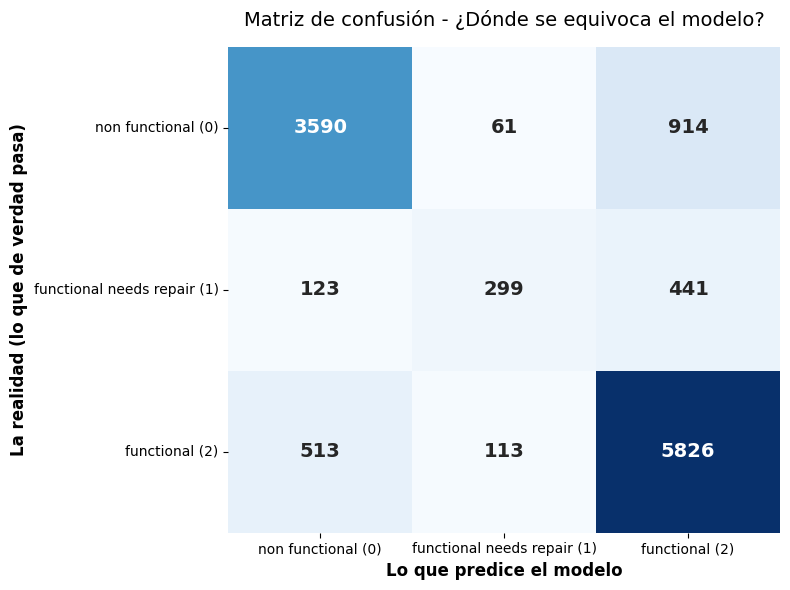

In [ ]:
# Matriz de confusión
cm = confusion_matrix(y_val, pred_val)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases,
            yticklabels=nombres_clases,
            cbar=False, annot_kws={"size": 14, "weight": "bold"})

plt.title('Matriz de confusión - ¿Dónde se equivoca el modelo?', fontsize=14, pad=15)
plt.xlabel('Lo que predice el modelo', fontsize=12, fontweight='bold')
plt.ylabel('La realidad (lo que de verdad pasa)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

El modelo es excelente detectando pozos completamente funcionales y pozos totalmente destruidos (los extremos de la diagonal). Sin embargo, la clase `functional needs repair` (pozos que funcionan pero necesitan reparación) es donde más falla el modelo, ya que al representar solo el 7% de los datos, el algoritmo a menudo los confunde con pozos sanos.
Este ejercicio es solo un concurso, pero un "falso negativo" en la vida real, es decir, en este caso catalogar a un pozo que está a punto de romperse como un pozo sano, tiene un coste altísimo ya que deja a una población sin agua.

Después de haber hecho 16 entregas, me he dado cuenta de que es infinitamente mejor inyectar conocimiento del mundo real (como proyectar las coordenadas en 3D o entender la naturaleza cíclica del tiempo) que usar algoritmos complejos o forzar variables de texto que acaban causando sobreajuste.

### **INTERPRETABILIDAD**

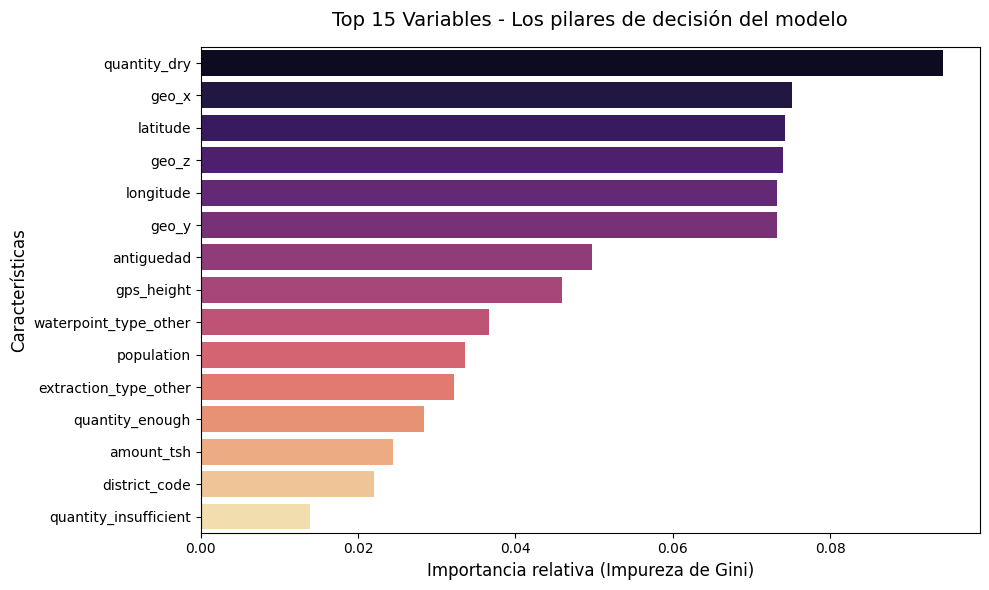

In [ ]:
# Extraemos las piezas del Pipeline
prep_extract = modelo_final.named_steps['preprocessor']
rf_extract = modelo_final.named_steps['classifier']

# Limpiamos los nombres generados por Scikit-Learn
nombres_limpios = [n.split('__')[-1] for n in prep_extract.get_feature_names_out()]

# Creamos el DataFrame de importancias
df_importancias = pd.DataFrame({
    'Variable': nombres_limpios,
    'Importancia': rf_extract.feature_importances_}).sort_values(by='Importancia', ascending=False)

# Lo visualizamos
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=df_importancias.head(15),
    palette='magma',
    hue='Variable',
    legend=False)
plt.title('Top 15 Variables - Los pilares de decisión del modelo', fontsize=14, pad=15)
plt.xlabel('Importancia relativa (Impureza de Gini)', fontsize=12)
plt.ylabel('Características', fontsize=12)
plt.tight_layout()
plt.show()

### **PREDICCIÓN Y EXPORTACIÓN**

In [ ]:
# Pasamos la misma función de limpieza que usamos al principio
X_test_limpio = limpieza(X_test_original)

# El pipeline hace la imputación, escalado, encoding y predicción automáticamente
predicciones_finales_num = modelo_final.predict(X_test_limpio)

mapeo_inverso = {0: 'non functional', 1: 'functional needs repair', 2: 'functional'}
predicciones_texto = pd.Series(predicciones_finales_num).map(mapeo_inverso)

# Compilación del CSV
df_entrega_final = pd.DataFrame({
    'id': X_test_original.index,
    'status_group': predicciones_texto})

nombre_archivo_master = 'JaimeDVM_PumpItUp_ModeloFinal.csv'
#df_entrega_final.to_csv(nombre_archivo_master, index=False)

df_entrega_final.head()

,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
